In [ ]:
import numpy as np
import random

field_width = 7
field_height = 7

field = np.zeros((field_width, field_height))
moves = {"0" : "up", "1": "down", "2": "left", "3": "right"}

moves_prey = {"up":np.array([0,-1]),"down":np.array([0,1]),"left":np.array([-1,0]),"right":np.array([1,0]),"still":np.array([0,0]), "smell":np.array([0,0])}
moves_hunter = {"up":np.array([0,-1]),"down":np.array([0,1]),"left":np.array([-1,0]),"right":np.array([1,0]),"flare":np.array([0,0])}

class Hunter:
    def __init__(self, x, y, sight,aware):
        self.position = np.array([x,y])
        self.sight = sight
        self.aware = aware
        self.detected = False
        self.flare_cd = 10

    def move(self,prey_pos,hunters, prey):
        valid_moves = []
        for move in moves_hunter.values():
                new_pos = self.position + move
                if 0 <= new_pos[0] < field_width and 0 <= new_pos[1] < field_height:
                    valid_moves.append(move)

            
        if not self.aware:
            if self.flare_cd == 0:
                direction = moves_hunter["flare"]
                self.flare_on(prey)
            else:
                direction = random.choice(valid_moves)
        else:
            direction = self.path_to_prey(prey_pos, valid_moves)

        if self.flare_cd > 0:
            self.flare_cd -= 1
        
        field[self.position[0]][self.position[1]] = 0
        self.position += direction
        field[self.position[0]][self.position[1]] = 2
        self.spotting(prey_pos)

    def spotting(self, prey_position): 
        if np.linalg.norm(self.position - prey_position) <= self.sight:
            self.aware = True
        else:
            self.aware = False
    
    def flare(self,prey,hunters):
        row = np.random.randint(field.shape[0])
        col = np.random.randint(field.shape[1])
        if np.linalg.norm(prey.position-field[row,col]) >= 1:
            print("flare worked")
            for hunter in hunters:
                hunter.aware = True
            prey.spotted = True
        self.flare_cd=10

    def flare_on(self,prey):
        row = np.random.randint(field.shape[0])
        col = np.random.randint(field.shape[1])
        flare_at=np.array((row,col))
        prey.flares.append(flare_at)

    def path_to_prey(self, prey_position, valid_moves):
        if not valid_moves:
            return np.array([0,0]) 
        min_dist = float("inf")
        best_move = random.choice(valid_moves)
        for move in valid_moves:
            dist = np.linalg.norm((self.position + move) - prey_position)
            if dist < min_dist:
                min_dist = dist
                best_move = move
        return best_move

            








class Prey:
    def __init__(self, x, y,sight,movement_speed):
        self.position = np.array([x,y])
        self.spotted = False
        self.previous_move = "still"
        self.current_move = "still"
        self.sight = 3
        self.movement_speed=movement_speed
        self.smell_cd = 0
        self.flares = []
        self.seen_flares= []

    def move(self, action,hunters):
        
        move = moves_prey[action]
        self.previous_move = self.current_move
        self.current_move=action
        new_pos = self.position + move

        if 0 <= new_pos[0] < field_width and 0 <= new_pos[1] < field_height and field[new_pos[0]][new_pos[1]] == 0:
            field[self.position[0]][self.position[1]] = 0
            self.position += move
            field[self.position[0]][self.position[1]] = 1
        if action == "smell":
            self.smell(hunters)
        else:
            self.detection(hunters)
            self.smell_cd = max(self.smell_cd - 1, 0)
        self.spotted = any(hunter.aware for hunter in hunters)  

    def get_valid_moves(self):

        valid_moves = []
        for move in moves_prey.keys():
            new_pos = self.position + moves_prey[move]
            if 0 <= new_pos[0] < field_width and 0 <= new_pos[1] < field_height:
                valid_moves.append(move)
        return valid_moves
    
    def smell(self,hunters):
        for hunter in hunters:
            hunter.detected = True
        self.smell_cd=5


    def detection(self,hunters):
        for hunter in hunters:
            if np.linalg.norm(hunter.position - self.position) <= self.sight:
                hunter.detected = True
            else:
                hunter.detected = False

    def get_position(self):
        return self.position
    
def reset_field(field_width, field_height):
    return np.zeros((field_width, field_height)) 



# def spawning(field_width, field_height):
#     global field  
#     field = reset_field(field_width, field_height) 
    
#     nbr_of_hunters = 3
#     xp = random.randint(0, field_width-1)
#     yp = random.randint(0, field_height-1)

#     sight = 4
#     player = Prey(xp, yp, 3, 2)
#     field[xp][yp] = 1

#     empty_cells = [(x, y) for x in range(field_width) for y in range(field_height) 
#                    if field[x][y] == 0 and np.linalg.norm(np.array([xp,yp]) - np.array([x,y])) > 3]
    
#     if len(empty_cells) < nbr_of_hunters:
#         empty_cells = [(x, y) for x in range(field_width) for y in range(field_height) if field[x][y] == 0]
    
#     chosen_cells = random.sample(empty_cells, min(nbr_of_hunters, len(empty_cells)))
#     hunters = []
    
#     for cells in chosen_cells:
#         hunters.append(Hunter(cells[0], cells[1], 2, False))
#         field[cells[0]][cells[1]] = 2  
        
#     return player, hunters



def spawning(field_width, field_height):
    global field  
    
    nbr_of_hunters = 3
    sight = 4
    Valid = False
    while not Valid:  
        field = reset_field(field_width, field_height) 
        

        xp = random.randint(0, field_width-1)
        yp = random.randint(0, field_height-1)
        player = Prey(xp, yp, 3, 2)
        field[xp][yp] = 1   

        empty_cells = [
            (x, y) 
            for x in range(field_width) 
            for y in range(field_height) 
            if field[x][y] == 0 and np.linalg.norm(np.array([xp, yp]) - np.array([x, y])) > 3
        ]
        
        if len(empty_cells) >= nbr_of_hunters:
            Valid = True   
    
    chosen_cells = random.sample(empty_cells, nbr_of_hunters)
    hunters = []
    
    for (hx, hy) in chosen_cells:
        hunters.append(Hunter(hx, hy, 2, False))
        field[hx][hy] = 2  
    
    return player, hunters


def start_game():
    player, hunters = spawning(field_height=field_height, field_width=field_width)
    number_of_turns = 50
    current_turn = 0
    caught = False
    while current_turn < number_of_turns and not caught:
        print("Turn:", current_turn)
        print("Field:\n", field.T)
        
        player.move(hunters)
        player.move(hunters)
        for hunter in hunters:
            hunter.move(player.get_position())
        current_turn += 1

        for hunter in hunters:
            if np.array_equal(hunter.position, player.position):
                print("Game Over")
                caught = True
                break
    if not caught:
        print("You survived!")
    else:
        print("You were caught by a hunter!")




In [85]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import random
from collections import deque
import matplotlib.pyplot as plt


field_width = 10
field_height = 10


class DQN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(DQN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, hidden_size)
        self.fc4 = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(0.1)
        
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        x = F.relu(self.fc3(x))
        x = self.fc4(x)
        return x

class DQNAgent:
    def __init__(self, state_size, action_size, lr=0.0001, gamma=0.95, epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.999):
        self.state_size = state_size
        self.action_size = action_size
        self.memory = deque(maxlen=10000)
        self.gamma = gamma   
        self.epsilon = epsilon  
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.learning_rate = lr
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        
        self.q_network = DQN(state_size, 256, action_size).to(self.device)
        self.target_network = DQN(state_size, 256, action_size).to(self.device)
        self.optimizer = optim.Adam(self.q_network.parameters(), lr=lr)
        
        self.update_target_network()
        
    def update_target_network(self):
        self.target_network.load_state_dict(self.q_network.state_dict())
    
    def remember(self, state, action, reward, next_state, done):
        self.memory.append((state, action, reward, next_state, done))


    def get_valid_actions(self, prey, field_width, field_height):
        x, y = prey.position
        valid = []
        if y > 0: valid.append(0)   #up
        if y < field_height - 1: valid.append(1) #down
        if x > 0: valid.append(2)   #left
        if x < field_width - 1: valid.append(3)  #right
        valid.append(4)  #still
        if prey.smell_cd == 0: valid.append(5) #smell
        return valid 

    def act(self, state, prey, field_width, field_height):
        
        if np.random.random() <= self.epsilon:
            valid_actions = self.get_valid_actions(prey,field_width,field_height)
            return random.choice(valid_actions)
        
        state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)
        q_values = self.q_network(state_tensor).cpu().data.numpy()[0]
        valid_actions = self.get_valid_actions(prey, field_width, field_height)
        invalid_actions = [a for a in range(self.action_size) if a not in valid_actions]
        q_values[invalid_actions] = -float("inf")

        return np.argmax(q_values)
    
    def replay(self, batch_size=32):
        if len(self.memory) < batch_size:
            return
            
        batch = random.sample(self.memory, batch_size)
        states = torch.FloatTensor([e[0] for e in batch]).to(self.device)
        actions = torch.LongTensor([e[1] for e in batch]).to(self.device)
        rewards = torch.FloatTensor([e[2] for e in batch]).to(self.device)
        next_states = torch.FloatTensor([e[3] for e in batch]).to(self.device)
        dones = torch.BoolTensor([e[4] for e in batch]).to(self.device)
        
        current_q_values = self.q_network(states).gather(1, actions.unsqueeze(1))
        next_q_values = self.target_network(next_states).max(1)[0].detach()
        target_q_values = rewards + (self.gamma * next_q_values * ~dones)
        
        loss = F.mse_loss(current_q_values.squeeze(), target_q_values)
        
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        
        if self.epsilon > self.epsilon_min:
            self.epsilon *= self.epsilon_decay

def get_state_representation(prey, hunters, field_width, field_height,remaining_moves):
    state = []
    
    prey_x, prey_y = prey.position
    state.extend([prey_x / field_width, prey_y / field_height])
    flare_count=0
    for flare in prey.flares:
        if any(np.array_equal(flare, seen) for seen in prey.seen_flares):
            state.extend([flare[0]/field_width, flare[1]/field_height])
            flare_count+=1
        else:
            state.extend([0,0])
            flare_count+=1
    
    while flare_count != 3:
        state.extend([0,0])
        flare_count += 1
    visible_hunters=0

    for hunter in hunters:
        if hunter.detected:
            visible_hunters += 1
    

    visible_count = visible_hunters / len(hunters)
    state.append(visible_count)

    state.append(remaining_moves / 2)
    
    max_hunters = len(hunters)  
    max_distance = np.sqrt(field_width**2 + field_height**2)
    state.append(prey.smell_cd/5)
    
    for hunter in hunters:
        if hunter.detected:
            hunter_x, hunter_y = hunter.position
            distance = np.linalg.norm(prey.position - hunter.position)
            
            normalized_distance = distance / max_distance
            state.append(normalized_distance)
            
            if distance > 0:
                direction_x = (hunter_x - prey_x) / distance
                direction_y = (hunter_y - prey_y) / distance
            else:
                direction_x, direction_y = 0, 0
            state.extend([direction_x, direction_y])
            
            state.append(1.0 if hunter.aware else 0.0)
        else:
            state.extend([0.0, 0.0, 0.0, 0.0])  
    
    dist_to_left = prey_x / field_width
    dist_to_right = (field_width - 1 - prey_x) / field_width
    dist_to_top = prey_y / field_height
    dist_to_bottom = (field_height - 1 - prey_y) / field_height
    state.extend([dist_to_left, dist_to_right, dist_to_top, dist_to_bottom])
    
    return np.array(state)

def calculate_reward(prey, hunters, caught, survived_turn, total_turns):

    
    if caught:
        return -300  
    
    if survived_turn == total_turns:
        return 100  
    
    reward = 1
    # if (prey.current_move == "still"):
    #     reward -= 5
    # min_distance = float('inf')
    # for hunter in hunters:
    #     distance = np.linalg.norm(prey.position - hunter.position)
    #     min_distance = min(min_distance, distance)
        
    #     if distance <= 1:
    #         reward -= 15
    #     elif distance <= 2:
    #         reward -= 5
    #     elif distance >= 3:
    #         reward += 2  
    
    #     if hunter.aware:
    #         reward -= 5
    # if all(not hunter.aware for hunter in hunters):
    #     reward += 25
    # prey_x, prey_y = prey.position
    
    # edge_distance = min(prey_x, prey_y, field_width - 1 - prey_x, field_height - 1 - prey_y)
    # if edge_distance >= 2:
    #     reward += 1
    
    return reward

def train_dqn_agent(episodes=2000, max_turns=50):
    action_names = ["up", "down", "left", "right", "still","smell"]
    action_size = len(action_names)
    
    num_hunters = 3
    state_size = 27
    
    agent = DQNAgent(state_size, action_size)
    scores = []
    survival_rates = []
    last_turns = []
    for episode in range(episodes):
        player, hunters = spawning(field_height=field_width ,field_width=field_width) 
        flared = False
        state = get_state_representation(player, hunters, field_width, field_height, 2)

        total_reward = 0
        caught = False
        actions_taken = []
        flares_succ=0
        total_flares=0
        for turn in range(max_turns):
            
            for i in range(player.movement_speed):

                action_idx = agent.act(state, player, field_width,field_height)
                action = action_names[action_idx]
                player.move(action,hunters)
                actions_taken.append(player.current_move)
                if player.flares:
                    for flare in player.flares:
                        if np.linalg.norm(player.position - flare) <= 1 and not any(np.array_equal(flare, seen) for seen in player.seen_flares):
                            player.seen_flares.append(flare)
                caught = any(np.array_equal(hunter.position, player.position) for hunter in hunters)
                done = caught or (turn + 1 == max_turns)

                next_state = get_state_representation(player, hunters, field_width, field_height, (player.movement_speed - (i+1)))
                reward = calculate_reward(player, hunters, caught, survived_turn=turn + 1, total_turns=max_turns)
                total_reward += reward
                agent.remember(state, action_idx, reward, next_state, done)
                state = next_state
                if done == True:
                    last_turns.append(turn+1)
                    break
            if done:
                break
            
            if player.flares or player.seen_flares:
                for flare in player.seen_flares:
                    if np.linalg.norm(player.position-flare) <= 1:
                        flared = True
                        flares_succ += 1
                total_flares += 1
                player.flares.clear()
                player.seen_flares.clear()

            for hunter in hunters:
                if flared:
                    hunter.aware = True
                    flared = False
                hunter.move(player.get_position(), hunters, player)
            
            caught = any(np.array_equal(hunter.position, player.position) for hunter in hunters)
            done = caught or (turn + 1 == max_turns)

            if player.flares:
                for flare in player.flares:
                    if np.linalg.norm(player.position - flare) <= 1:
                        player.seen_flares.append(flare)
            
            
            next_state = get_state_representation(player, hunters, field_width, field_height, 0)
            total_reward += calculate_reward(player, hunters, caught, turn + 1, max_turns)

            done = caught or (turn + 1 == max_turns)
            agent.remember(state, action_idx, reward, next_state, done)
            
            state = next_state
            
            
            if done:
                last_turns.append(turn + 1)
                break
        
            if len(agent.memory) > 32 and turn % 5 == 0:
                agent.replay(32)
        
        if episode % 50 == 0:
            agent.update_target_network()
        
        scores.append(total_reward)
        survived = not caught
        survival_rates.append(survived)
        
        if episode % 100 == 0 and episode != 0:
            avg_score = np.mean(scores[-100:])
            avg_turns = np.mean(last_turns[-100:]) if last_turns else 0
            survival_rate = np.mean(survival_rates[-100:]) * 100
            last_turns = []
            print(f"Episode {episode}, Average Score: {avg_score:.2f}, Survival Rate: {survival_rate:.1f}%, Epsilon: {agent.epsilon:.3f}, Avg Turns: {avg_turns:.1f}")
            print(f"Succesful flares {flares_succ} vs total flares {total_flares} ")
            print(f"Moves Taken {actions_taken}")
            print(f"Prey was {'caught' if caught else 'not caught'}")
            flares_succ=0
            total_flares=0
            
    return agent, scores, survival_rates

In [86]:
def test_agent(agent, episodes=100):
    action_names = ["up", "down", "left", "right", "still"]
    agent.epsilon = 0  
    
    survival_count = 0
    
    for episode in range(episodes):
        player, hunters = spawning(field_height=field_height, field_width=field_width)
        state = get_state_representation(player, hunters, field_width, field_height, 2)
        caught = False
        
        for turn in range(50):  
            for i in range(player.movement_speed):
                action_idx = agent.act(state, player, field_width,field_height)
                action = action_names[action_idx]
                player.move(action,hunters)
                
                next_state = get_state_representation(player, hunters, field_width, field_height)

            
            for hunter in hunters:
                hunter.move(player.get_position())
            
            caught = any(np.array_equal(hunter.position, player.position) for hunter in hunters)
            if caught:
                break
                
            state = get_state_representation(player, hunters, field_width, field_height)

        if not caught:
            survival_count += 1
    

    survival_rate = (survival_count / episodes) * 100
    print(f"Test Results: {survival_count}/{episodes} games survived ({survival_rate:.1f}%)")
    return survival_rate

Episode 100, Average Score: -183.39, Survival Rate: 14.0%, Epsilon: 0.654, Avg Turns: 20.6
Succesful flares 2 vs total flares 38 
Moves Taken ['left', 'still', 'right', 'right', 'right', 'left', 'left', 'down', 'left', 'right', 'right', 'down', 'smell', 'right', 'still', 'left', 'down', 'down', 'smell', 'up', 'right', 'down', 'up', 'left', 'right', 'left', 'smell', 'right', 'left', 'left', 'right', 'still', 'right', 'still', 'still', 'down', 'smell', 'left', 'right', 'still', 'still', 'up', 'down', 'left', 'right', 'up', 'smell', 'left', 'right', 'left', 'right', 'left', 'right', 'up', 'smell', 'down', 'left', 'down', 'left', 'left', 'right', 'up', 'down', 'still', 'right', 'still', 'still', 'right', 'left', 'smell', 'right', 'still', 'left', 'right', 'up', 'left', 'smell', 'still', 'right', 'down', 'still', 'up', 'left', 'right', 'left', 'right', 'left', 'right', 'still', 'still', 'left', 'up', 'smell', 'right', 'left', 'left', 'right', 'up', 'down']
Prey was not caught
Episode 200, A

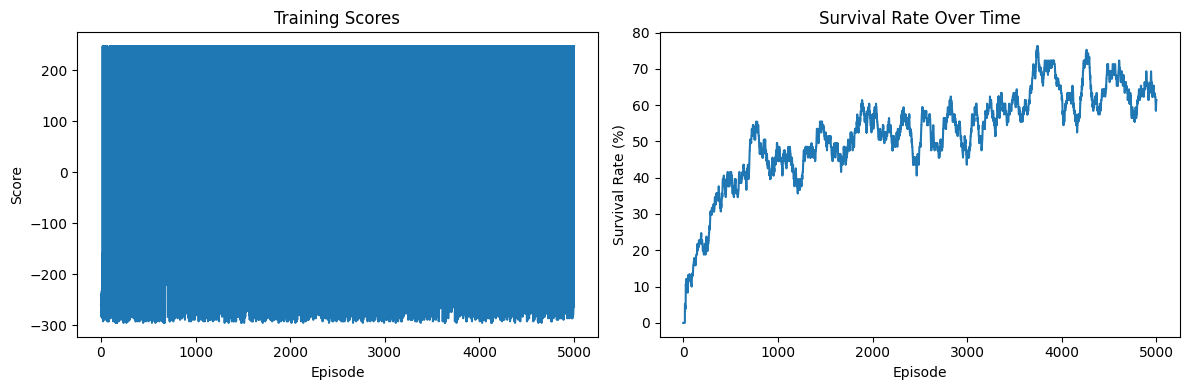

In [87]:
if __name__ == "__main__":


    agent, scores, survival_rates = train_dqn_agent(episodes=5000)

    #test_agent(agent, episodes=100)
    
    torch.save(agent.q_network.state_dict(), 'prey_dqn_model.pth')
    
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(scores)
    plt.title('Training Scores')
    plt.xlabel('Episode')
    plt.ylabel('Score')
    
    plt.subplot(1, 2, 2)
    window_size = 100
    rolling_survival = [np.mean(survival_rates[max(0, i-window_size):i+1]) * 100 
                       for i in range(len(survival_rates))]
    plt.plot(rolling_survival)
    plt.title('Survival Rate Over Time')
    plt.xlabel('Episode')
    plt.ylabel('Survival Rate (%)')
    
    plt.tight_layout()
    plt.show()

In [88]:
agent = torch.load("milestones\Smell.pth")

C:\Users\hamza\AppData\Local\Temp\ipykernel_29016\653199044.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  agent = torch.load("milestones\Smell.pth")


In [89]:
import tkinter as tk
from tkinter import ttk
import numpy as np

class GameGUI:
    def __init__(self):
        self.root = tk.Tk()
        self.root.title("Prey vs Hunters - Visual Testing")
        self.root.geometry("1200x1200")
        self.root.configure(bg='#2c3e50')

        # Game state
        self.player = None
        self.hunters = []
        self.turn = 0
        self.max_turns = 50
        self.game_over = False
        self.caught = False

        # Use existing agent
        self.agent = agent

        self.setup_ui()
        self.new_game()

    def setup_ui(self):
        main_frame = tk.Frame(self.root, bg='#2c3e50')
        main_frame.pack(fill=tk.BOTH, expand=True, padx=10, pady=10)

        title_label = tk.Label(main_frame, text="🏃 Prey vs Hunters 🔍",
                              font=('Arial', 18, 'bold'),
                              bg='#2c3e50', fg='white')
        title_label.pack(pady=10)

        stats_frame = tk.Frame(main_frame, bg='#34495e', relief=tk.RAISED, bd=2)
        stats_frame.pack(fill=tk.X, pady=5)

        self.turn_label = tk.Label(stats_frame, text="Turn: 0",
                                  font=('Arial', 12), bg='#34495e', fg='white')
        self.turn_label.pack(side=tk.LEFT, padx=10, pady=5)

        self.status_label = tk.Label(stats_frame, text="Status: Running",
                                    font=('Arial', 12), bg='#34495e', fg='#2ecc71')
        self.status_label.pack(side=tk.LEFT, padx=10, pady=5)

        self.aware_label = tk.Label(stats_frame, text="Hunters Aware: 0/3",
                                   font=('Arial', 12), bg='#34495e', fg='white')
        self.aware_label.pack(side=tk.LEFT, padx=10, pady=5)

        self.distance_label = tk.Label(stats_frame, text="Min Distance: -",
                                      font=('Arial', 12), bg='#34495e', fg='white')
        self.distance_label.pack(side=tk.LEFT, padx=10, pady=5)

        grid_frame = tk.Frame(main_frame, bg='#2c3e50')
        grid_frame.pack(expand=True, pady=10)

        self.canvas = tk.Canvas(grid_frame, width=500, height=500, bg='#34495e')
        self.canvas.pack()

        control_frame = tk.Frame(main_frame, bg='#2c3e50')
        control_frame.pack(fill=tk.X, pady=10)

        self.new_game_btn = tk.Button(control_frame, text="🎮 New Game",
                                     command=self.new_game, font=('Arial', 12),
                                     bg='#3498db', fg='white', relief=tk.FLAT, padx=20)
        self.new_game_btn.pack(side=tk.LEFT, padx=5)

        self.next_turn_btn = tk.Button(control_frame, text="▶️ Next Turn",
                                      command=self.next_turn, font=('Arial', 12),
                                      bg='#2ecc71', fg='white', relief=tk.FLAT, padx=20)
        self.next_turn_btn.pack(side=tk.LEFT, padx=5)

        self.auto_play_btn = tk.Button(control_frame, text="⏯️ Auto Play",
                                      command=self.toggle_auto_play, font=('Arial', 12),
                                      bg='#f39c12', fg='white', relief=tk.FLAT, padx=20)
        self.auto_play_btn.pack(side=tk.LEFT, padx=5)

        legend_frame = tk.Frame(main_frame, bg='#2c3e50')
        legend_frame.pack(fill=tk.X)

        legend_text = "🟢 = Prey (You) | 🔴 = Hunter | 🟠 = Aware Hunter"
        legend_label = tk.Label(legend_frame, text=legend_text,
                               font=('Arial', 10), bg='#2c3e50', fg='#bdc3c7')
        legend_label.pack(pady=5)

        self.auto_play_active = True

    def new_game(self):
        global field, field_width, field_height
        # Use existing spawning function and field
        self.player, self.hunters = spawning(field_height, field_width)
        self.turn = 0
        self.game_over = False
        self.caught = False
        self.auto_play_active = True
        self.auto_play_btn.config(text="⏯️ Auto Play")
        self.update_display()

    def next_turn(self):
        if self.game_over:
            return

        for i in range(self.player.movement_speed):
            if self.agent:
                state = get_state_representation(self.player, self.hunters,
                                                 field_width, field_height,
                                                 self.player.movement_speed - (i+1))
                action_idx = self.agent.act(state, self.player, field_width, field_height)
                action_names = ["up", "down", "left", "right", "still", "smell"]
                action = action_names[action_idx]
            else:
                action = "still"

            self.player.move(action, self.hunters)
            if any(np.array_equal(hunter.position, self.player.position) for hunter in self.hunters):
                self.game_over = True
                self.caught = True
                break

        if not self.game_over:
            for hunter in self.hunters:
                hunter.move(self.player.get_position(), self.hunters,self.player)

            self.turn += 1

            if any(np.array_equal(hunter.position, self.player.position) for hunter in self.hunters):
                self.game_over = True
                self.caught = True
            elif self.turn >= self.max_turns:
                self.game_over = True
                self.caught = False

        self.update_display()
        if self.game_over:
            self.show_game_over()

    def update_display(self):
        self.canvas.delete("all")
        cell_size = min(480 // field_width, 480 // field_height)
        offset_x = (500 - cell_size * field_width) // 2
        offset_y = (500 - cell_size * field_height) // 2

        for x in range(field_width):
            for y in range(field_height):
                x1 = offset_x + x * cell_size
                y1 = offset_y + y * cell_size
                x2 = x1 + cell_size
                y2 = y1 + cell_size
                self.canvas.create_rectangle(x1, y1, x2, y2,
                                            fill='#4a6fa5', outline='#2c3e50', width=2)

        for x in range(field_width):
            for y in range(field_height):
                x1 = offset_x + x * cell_size
                y1 = offset_y + y * cell_size
                center_x = x1 + cell_size // 2
                center_y = y1 + cell_size // 2

                if field[x][y] == 1:  # Prey
                    self.canvas.create_oval(center_x - 15, center_y - 15,
                                           center_x + 15, center_y + 15,
                                           fill='#2ecc71', outline='white', width=3)
                    self.canvas.create_text(center_x, center_y, text="P",
                                           fill='white', font=('Arial', 12, 'bold'))
                elif field[x][y] == 2:  # Hunter
                    hunter = None
                    for h in self.hunters:
                        if h.position[0] == x and h.position[1] == y:
                            hunter = h
                            break
                    color = '#e74c3c' if (hunter and hunter.aware) else '#c0392b'
                    self.canvas.create_rectangle(center_x - 15, center_y - 15,
                                                center_x + 15, center_y + 15,
                                                fill=color, outline='white', width=3)
                    text = "!" if (hunter and hunter.aware) else "H"
                    self.canvas.create_text(center_x, center_y, text=text,
                                           fill='white', font=('Arial', 12, 'bold'))

        self.turn_label.config(text=f"Turn: {self.turn}")

        if self.game_over:
            status = "WON!" if not self.caught else "CAUGHT!"
            color = '#2ecc71' if not self.caught else '#e74c3c'
            self.status_label.config(text=f"Status: {status}", fg=color)
        else:
            self.status_label.config(text="Status: Running", fg='#2ecc71')

        aware_count = sum(1 for h in self.hunters if h.aware)
        self.aware_label.config(text=f"Hunters Aware: {aware_count}/{len(self.hunters)}")

        min_dist = min(np.linalg.norm(self.player.position - h.position) for h in self.hunters)
        self.distance_label.config(text=f"Min Distance: {min_dist:.1f}")

        self.next_turn_btn.config(state=tk.DISABLED if self.game_over else tk.NORMAL)

    def show_game_over(self):
        message = "🎉 You Survived!" if not self.caught else "💀 You Were Caught!"
        popup = tk.Toplevel(self.root)
        popup.title("Game Over")
        popup.geometry("300x150")
        popup.configure(bg='#2c3e50')
        popup.transient(self.root)
        popup.grab_set()
        popup.update_idletasks()
        x = (popup.winfo_screenwidth() // 2) - (popup.winfo_width() // 2)
        y = (popup.winfo_screenheight() // 2) - (popup.winfo_height() // 2)
        popup.geometry(f"+{x}+{y}")

        tk.Label(popup, text=message, font=('Arial', 16, 'bold'),
                 bg='#2c3e50', fg='white').pack(pady=20)
        tk.Label(popup, text=f"Survived {self.turn} turns", font=('Arial', 12),
                 bg='#2c3e50', fg='#bdc3c7').pack(pady=5)
        tk.Button(popup, text="Play Again", command=lambda: [popup.destroy(), self.new_game()],
                  font=('Arial', 12), bg='#3498db', fg='white', relief=tk.FLAT, padx=20).pack(pady=10)

    def toggle_auto_play(self):
        if self.auto_play_active:
            self.auto_play_active = False
            self.auto_play_btn.config(text="⏯️ Auto Play")
        else:
            self.auto_play_active = True
            self.auto_play_btn.config(text="⏸️ Stop Auto")
            self.auto_play()

    def auto_play(self):
        if self.auto_play_active and not self.game_over:
            self.next_turn()
            self.root.after(800, self.auto_play)
        else:
            self.auto_play_active = False
            self.auto_play_btn.config(text="⏯️ Auto Play")

    def run(self):
        self.root.mainloop()

# Usage example
gui = GameGUI()
gui.run()


Exception in Tkinter callback
Traceback (most recent call last):
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.10_3.10.3056.0_x64__qbz5n2kfra8p0\lib\tkinter\__init__.py", line 1921, in __call__
    return self.func(*args)
  File "C:\Users\hamza\AppData\Local\Temp\ipykernel_29016\3557644705.py", line 108, in next_turn
    action_idx = self.agent.act(state, self.player, field_width, field_height)
AttributeError: 'collections.OrderedDict' object has no attribute 'act'
Exception in Tkinter callback
Traceback (most recent call last):
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.10_3.10.3056.0_x64__qbz5n2kfra8p0\lib\tkinter\__init__.py", line 1921, in __call__
    return self.func(*args)
  File "C:\Users\hamza\AppData\Local\Temp\ipykernel_29016\3557644705.py", line 108, in next_turn
    action_idx = self.agent.act(state, self.player, field_width, field_height)
AttributeError: 'collections.OrderedDict' object has no attribute 'act'
Exception 